In [33]:
import pandas as pd

df = pd.read_csv('valorant-stats.csv')
df

,Name,Weapon Type,Price,Fire Rate,Wall Penetration,Magazine Capacity,HDMG_0,BDMG_0,LDMG_0,HDMG_1,BDMG_1,LDMG_1,HDMG_2,BDMG_2,LDMG_2
0,Classic,Sidearm,0,6.75,Low,12,78,26,22,78,26,22,66,22,18
1,Shorty,Sidearm,200,3.30,Low,2,36,12,10,24,8,6,9,3,2
2,Frenzy,Sidearm,400,10.00,Low,13,78,26,22,63,21,17,63,21,17
3,Ghost,Sidearm,500,6.75,Medium,15,105,33,26,88,25,21,88,25,21
4,Sheriff,Sidearm,800,4.00,High,6,160,55,47,160,55,47,145,50,43
5,Stinger,SMG,1000,18.00,Low,20,67,27,23,62,25,21,62,25,21
6,Spectre,SMG,1600,13.33,Medium,30,78,26,22,66,22,18,66,22,18
7,Bulldog,Rifle,2100,9.15,Medium,24,116,35,30,116,35,30,116,35,30
8,Guardian,Rifle,2500,6.50,Medium,12,195,65,49,195,65,49,195,65,49
9,Phantom,Rifle,2900,11.00,Medium,30,156,39,33,140,35,30,124,31,26


In [34]:
# EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()} \n')

print(f'Cek duplicated data \n {df.duplicated().sum()}')

Cek 5 data teratas 
       Name Weapon Type  Price  Fire Rate Wall Penetration  Magazine Capacity  \
0  Classic     Sidearm      0       6.75              Low                 12   
1   Shorty     Sidearm    200       3.30              Low                  2   
2   Frenzy     Sidearm    400      10.00              Low                 13   
3    Ghost     Sidearm    500       6.75           Medium                 15   
4  Sheriff     Sidearm    800       4.00             High                  6   

   HDMG_0  BDMG_0  LDMG_0  HDMG_1  BDMG_1  LDMG_1  HDMG_2  BDMG_2  LDMG_2  
0      78      26      22      78      26      22      66      22      18  
1      36      12      10      24       8       6       9       3       2  
2      78      26      22      63      21      17      63      21      17  
3     105      33      26      88      25      21      88      25      21  
4     160      55      47     160      55      47     145      50      43   

Cek tipe data 
 Name                    

In [35]:
# cleaning data
df=df.drop(columns=['Name', 'Weapon Type'])

In [36]:
# outlier
numerical_columns = df.select_dtypes(include='number').columns

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    outlier_summary.append({
        'kolom': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'batas_bawah': lower_bound,
        'batas_atas': upper_bound,
        'jumlah_outlier': len(outliers),
        'persen_outlier': round(len(outliers) / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,Price,800.0,2500.0,1700.0,-1750.00,5050.00,0,0.00
1,Fire Rate,3.5,10.0,6.5,-6.25,19.75,0,0.00
2,Magazine Capacity,6.0,25.0,19.0,-22.50,53.50,1,5.88
3,HDMG_0,72.0,156.0,84.0,-54.00,282.00,0,0.00
4,BDMG_0,26.0,39.0,13.0,6.50,58.50,3,17.65
5,LDMG_0,22.0,33.0,11.0,5.50,49.50,2,11.76
6,HDMG_1,63.0,156.0,93.0,-76.50,295.50,0,0.00
7,BDMG_1,22.0,39.0,17.0,-3.50,64.50,3,17.65
8,LDMG_1,18.0,33.0,15.0,-4.50,55.50,2,11.76
9,HDMG_2,63.0,145.0,82.0,-60.00,268.00,0,0.00


In [37]:
# handle outlier
numerical_columns = df.select_dtypes(include='number').columns

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
)

outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_mask.sum(),
    'Percentage': outlier_mask.mean() * 100
})

outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
)

,Outlier Count,Percentage
BDMG_1,3,17.647059
BDMG_2,3,17.647059
BDMG_0,3,17.647059
LDMG_0,2,11.764706
LDMG_2,2,11.764706
LDMG_1,2,11.764706
Magazine Capacity,1,5.882353
Price,0,0.000000
HDMG_0,0,0.000000
Fire Rate,0,0.000000


In [44]:
# split data
x = df.drop(columns = ['Price'])
y = df['Price']

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

In [47]:
# encoding
df['Wall Penetration'] = df['Wall Penetration'].map({'Low': 0, 'Medium': 1, 'High': 2})

In [50]:
# training model
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, ShuffleSplit

model = make_pipeline(StandardScaler(), Ridge(alpha=5))

cv = ShuffleSplit(n_splits=200, test_size=0.25, random_state=42)
scores = cross_val_score(model, x, y, cv=cv, scoring='neg_root_mean_squared_error')
print('RMSE rata-rata:', -scores.mean())

model.fit(x, y)   # fit ke seluruh data kalau mau dipakai buat prediksi

RMSE rata-rata: 1115.6547868083935


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Fire Rate','Wall Penetration','Magazine Capacity',...,'HDMG_2','BDMG_2', 'LDMG_2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [53]:
# apply and evaluate
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

model = make_pipeline(StandardScaler(), Ridge(alpha=5))
model.fit(x_train, y_train)          # training

pred_test = model.predict(x_test)    # apply ke data baru

mean_absolute_error(y_test, pred_test)
np.sqrt(mean_squared_error(y_test, pred_test))   # RMSE
r2_score(y_test, pred_test)

-2.415497302896084

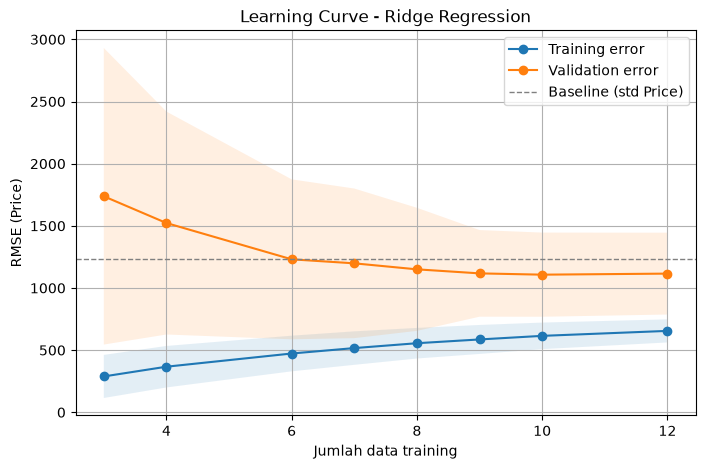

In [55]:
# learning curve (Ridge Regression)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import learning_curve, ShuffleSplit

model = make_pipeline(StandardScaler(), Ridge(alpha=5))
cv = ShuffleSplit(n_splits=200, test_size=0.25, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    model, x, y,
    train_sizes=np.linspace(0.3, 1.0, 8),
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

train_rmse = -train_scores
val_rmse = -val_scores

plt.figure(figsize=(8, 5))
for scores, label in [(train_rmse, 'Training error'), (val_rmse, 'Validation error')]:
    m, s = scores.mean(axis=1), scores.std(axis=1)
    plt.plot(train_sizes, m, 'o-', label=label)
    plt.fill_between(train_sizes, m - s, m + s, alpha=0.12)

plt.axhline(y.std(), color='gray', ls='--', lw=1, label='Baseline (std Price)')
plt.xlabel('Jumlah data training')
plt.ylabel('RMSE (Price)')
plt.title('Learning Curve - Ridge Regression')
plt.legend()
plt.grid(True)
plt.show()